In [ ]:
import re
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# Загружаем сырой датасет
df_raw = pd.read_csv('../data/olx_laptops_expanded.csv')
print(f"Исходный размер датасета: {df_raw.shape[0]} строк, {df_raw.shape[1]} колонок")
display(df_raw.head(5))

Исходный размер датасета: 5406 строк, 6 колонок


,title,price_kzt,city,location_date_raw,url,search_source
0,ASUS Vivobook i3-1315U / 20GB RAM / SSD 512GB ...,170000,Алматы,"Алматы, Бостандыкский район - 28 сентября 2026 г.",https://www.olx.kz/d/obyavlenie/asus-vivobook-...,Общий каталог
1,Ноутбук для игр ASUS TUF Gaming 15 | Ryzen 5-7...,336000,Астана,"Астана, Алматинский район - 27 сентября 2026 г.",https://www.olx.kz/d/obyavlenie/noutbuk-dlya-i...,Общий каталог
2,Ноутбук Zik Ноутбуки в наличии.,30000,Павлодар,Павлодар - Сегодня в 13:27,https://www.olx.kz/d/obyavlenie/noutbuk-zik-no...,Общий каталог
3,Продам плоншет в Алмате,25000,Казахстан,Казахстан - Сегодня в 15:50,https://www.olx.kz/d/obyavlenie/prodam-plonshe...,Общий каталог
4,Ноутбук Acer | Core i3 | SSD 256Gb | ОЗУ 8Gb,85000,Астана,"Астана, Нура - Сегодня в 15:49",https://www.olx.kz/d/obyavlenie/noutbuk-acer-c...,Общий каталог


In [2]:
# 1. Удаляем полные дубликаты объявлений
df_clean = df_raw.drop_duplicates(subset=['title', 'price_kzt', 'city']).copy()

# 2. Удаляем нерелевантные товары (аксессуары, запчасти, планшеты, услуги ремонта/скупки)
garbage_words = (
    r'пл[оа]ншет|сумк[аи]|рюкзак|зарядк[аи]|блок питания|матриц[аы]|'
    r'клавиатур[аы]|ремонт|скупка|выкуп|аренд[аы]|на запчасти|разбор|'
    r'подставк[аи]|охлаждени[ея]|системный блок'
)
mask_garbage = df_clean['title'].str.lower().str.contains(garbage_words, regex=True)
df_clean = df_clean[~mask_garbage].copy()

# 3. Убираем нереалистичные цены (ниже 25 000 тг — это сломанные/запчасти, выше 2.2 млн тг — единичные выбросы)
df_clean = df_clean[(df_clean['price_kzt'] >= 25000) & (df_clean['price_kzt'] <= 2200000)].copy()

print(f"Удалено дубликатов и мусора: {len(df_raw) - len(df_clean)} строк")
print(f"Осталось чистых объявлений о продаже ноутбуков: {len(df_clean)}")

Удалено дубликатов и мусора: 108 строк
Осталось чистых объявлений о продаже ноутбуков: 5298


In [ ]:
def create_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    
    # Объединяем заголовок, транслит из URL-ссылки и категорию поиска в единую строку в нижнем регистре
    url_slug = d['url'].str.extract(r'obyavlenie/([a-z0-9\-]+)-ID')[0].fillna('').str.replace('-', ' ')
    full_text = (d['title'].str.lower() + ' ' + url_slug + ' ' + d['search_source'].str.lower())
    title_low = d['title'].str.lower()

    # 1. Бренд ноутбука
    def parse_brand(txt):
        if re.search(r'\b(apple|macbook|макбук|mac)\b', txt): return 'Apple'
        if re.search(r'\b(asus|асус|rog|tuf|vivobook|zenbook|zephyrus)\b', txt): return 'ASUS'
        if re.search(r'\b(lenovo|леново|legion|легион|ideapad|thinkpad|loq|yoga)\b', txt): return 'Lenovo'
        if re.search(r'\b(acer|асер|эйсер|nitro|нитро|predator|aspire|swift)\b', txt): return 'Acer'
        if re.search(r'\b(hp|хп|victus|виктус|omen|омен|pavilion|probook|elitebook|envy)\b', txt): return 'HP'
        if re.search(r'\b(msi|мси|katana|cyborg|thin|stealth|raider|pulse|sword|gf63|gf65)\b', txt): return 'MSI'
        if re.search(r'\b(dell|делл|alienware|inspiron|latitude|xps)\b', txt): return 'Dell'
        if re.search(r'\b(huawei|matebook|honor|magicbook|xiaomi|redmibook)\b', txt): return 'Huawei/Honor/Xiaomi'
        if re.search(r'\b(gigabyte|aorus|thunderobot|machinike|machenike|ardor)\b', txt): return 'Gaming_Tier2'
        return 'Other'

    d['brand'] = full_text.apply(parse_brand)

    # 2. Линейка / Позиционирование ноутбука
    def parse_lineup(txt):
        if re.search(r'\b(rog|strix|scar|zephyrus|alienware|raider|aorus|legion pro|legion 7|legion 9|predator|omen)\b', txt):
            return 'Flagship_Gaming'
        if re.search(r'\b(tuf|nitro|legion|victus|katana|cyborg|loq|gf63|gf65|thin|thunderobot|machenike|ardor|игровой)\b', txt):
            return 'Mid_Gaming'
        if re.search(r'\b(macbook pro|pro m[1-5]|zenbook|xps|thinkpad|elitebook|yoga)\b', txt):
            return 'Premium_Ultrabook'
        if re.search(r'\b(macbook air|air m[1-5]|vivobook|ideapad|aspire|pavilion|matebook|magicbook)\b', txt):
            return 'Mainstream_Book'
        return 'Budget_Office'

    d['lineup'] = full_text.apply(parse_lineup)

    # 3. Видеокарта и ее индекс мощности (gpu_score от 0 до 12)
    def parse_gpu(txt):
        if re.search(r'rtx\s*5090|rtx\s*5080|rtx\s*4090', txt): return ('RTX 4090 / 5080+', 12.0)
        if re.search(r'rtx\s*5070\s*ti|rtx\s*4080', txt): return ('RTX 4080 / 5070Ti', 11.0)
        if re.search(r'rtx\s*5070|rtx\s*3080', txt): return ('RTX 3080 / 5070', 10.0)
        if re.search(r'rtx\s*5060|rtx\s*4070', txt): return ('RTX 4070 / 5060', 9.0)
        if re.search(r'rtx\s*3070', txt): return ('RTX 3070 / 3070Ti', 8.0)
        if re.search(r'rtx\s*4060', txt): return ('RTX 4060', 7.0)
        if re.search(r'rtx\s*4050', txt): return ('RTX 4050', 6.0)
        if re.search(r'rtx\s*3060', txt): return ('RTX 3060', 5.5)
        if re.search(r'rtx\s*3050|rtx\s*2060|rtx\s*2070|rx\s*6[67]00', txt): return ('RTX 3050 / 2060', 4.5)
        if re.search(r'rtx\s*2050|gtx\s*1660', txt): return ('GTX 1660Ti / RTX 2050', 3.5)
        if re.search(r'gtx\s*1650|gtx\s*1070|gtx\s*1060', txt): return ('GTX 1650 / 1060', 3.0)
        if re.search(r'gtx\s*1050|gtx\s*9[5678]0|mx\s*[2345][0-9]0', txt): return ('GTX 1050 / MX', 2.0)
        return ('Integrated_or_NotSpecified', 0.0)

    gpu_parsed = full_text.apply(parse_gpu)
    d['gpu_exact'] = [g[0] for g in gpu_parsed]
    d['gpu_score'] = [g[1] for g in gpu_parsed]

    # 4. Процессор, уровень мощности (cpu_tier) и примерный год выпуска (est_year)
    def parse_cpu(txt):
        # Процессоры Apple M1 - M5
        m_chip = re.search(r'\bm([1-5])\s*(pro|max)?\b', txt)
        if m_chip:
            gen = int(m_chip.group(1))
            is_pro = 2 if m_chip.group(2) in ['pro', 'max'] else 0
            return (f"Apple M{gen}", 5 + gen + is_pro, 2020 + gen)
        if re.search(r'ultra\s*[579]', txt):
            return ('Intel Core Ultra', 9, 2024)
        # Intel Core i3/i5/i7/i9 с указанием поколения (например i5-12500H)
        intel_full = re.search(r'i([3579])[-\s]*(1[0-4]|[2-9])[0-9]{2,3}', txt)
        if intel_full:
            lvl, gen = int(intel_full.group(1)), int(intel_full.group(2))
            return (f"Core i{lvl}", (lvl // 2) + max(0, gen - 8), min(2025, 2010 + gen))
        # Intel Core без точного индекса модели
        intel_short = re.search(r'(?:core\s*|\b)i([3579])\b', txt)
        if intel_short:
            lvl = int(intel_short.group(1))
            return (f"Core i{lvl}", (lvl // 2) + 2, 2020)
        # AMD Ryzen 3/5/7/9
        ryzen_full = re.search(r'(?:ryzen|райзен|r)\s*([3579])[-\s]*([3-9])[0-9]{3}', txt)
        if ryzen_full:
            lvl, ser = int(ryzen_full.group(1)), int(ryzen_full.group(2))
            return (f"Ryzen {lvl}", (lvl // 2) + max(0, ser - 2), min(2025, 2016 + ser))
        ryzen_short = re.search(r'(?:ryzen|райзен)\s*([3579])\b', txt)
        if ryzen_short:
            lvl = int(ryzen_short.group(1))
            return (f"Ryzen {lvl}", (lvl // 2) + 3, 2021)
        if re.search(r'\b(celeron|pentium|athlon|n[145][0-9]{2,3}|phenom)\b', txt):
            return ('Budget_CPU', 1, 2018)
        return ('Unknown_CPU', 3, 2020)

    cpu_parsed = full_text.apply(parse_cpu)
    d['cpu_family'] = [c[0] for c in cpu_parsed]
    d['cpu_tier'] = [c[1] for c in cpu_parsed]
    d['est_year'] = [c[2] for c in cpu_parsed]

    # 5. Оперативная память (RAM, ГБ) и накопитель (SSD, ГБ)
    def parse_ram(txt):
        for pat in [
            r'(?:озу|ram|ddr[45]?)\s*[:\-]?\s*(4|8|12|16|20|24|32|64)\b',
            r'\b(4|8|12|16|24|32|64)\s*(?:gb|гб)?\s*(?:озу|ram|ddr[45]?)\b',
            r'\b(4|8|12|16|24|32|64)\s*(?:gb|гб)?\s*[/|\\•]\s*(?:ssd\s*)?(?:128|256|512|1000|1024|1tb|1тб)',
            r'\b(16|24|32|64)\s*(?:gb|гб)\b'
        ]:
            m = re.search(pat, txt)
            if m: return float(m.group(1))
        return np.nan

    def parse_ssd(txt):
        if re.search(r'\b(2\s*(?:tb|тб)|2000|2048)\b', txt): return 2048.0
        if re.search(r'\b(1\s*(?:tb|тб)|1000|1024)\b', txt): return 1024.0
        if re.search(r'\b(512|500)\s*(?:gb|гб|ssd|nvme)?\b', txt): return 512.0
        if re.search(r'\b(256|250|240)\s*(?:gb|гб|ssd)?\b', txt): return 256.0
        if re.search(r'\b(128|120)\s*(?:gb|гб|ssd)?\b', txt): return 128.0
        return np.nan

    d['ram_gb_raw'] = full_text.apply(parse_ram)
    d['ssd_gb_raw'] = full_text.apply(parse_ssd)

    # Считаем Индекс полноты описания (сколько параметров продавец реально указал в заголовке: от 0 до 5)
    d['spec_detail_score'] = (
        (d['brand'] != 'Other').astype(int) +
        (d['cpu_family'] != 'Unknown_CPU').astype(int) +
        (d['gpu_score'] > 0).astype(int) +
        (d['ram_gb_raw'].notna()).astype(int) +
        (d['ssd_gb_raw'].notna()).astype(int)
    )
    
    # Флаг информативного объявления (где указана видеокарта ИЛИ процессор вместе с памятью/MacBook)
    d['is_informative'] = (
        (d['gpu_score'] > 0) |
        ((d['cpu_family'] != 'Unknown_CPU') & (d['ram_gb_raw'].notna() | d['ssd_gb_raw'].notna() | (d['brand'] == 'Apple')))
    ).astype(int)

    # Заполняем пропуски ОЗУ и SSD медианой по соответствующей линейке
    d['ram_gb'] = d.groupby('lineup')['ram_gb_raw'].transform(lambda x: x.fillna(x.median())).fillna(8.0)
    d['ssd_gb'] = d.groupby('lineup')['ssd_gb_raw'].transform(lambda x: x.fillna(x.median())).fillna(512.0)

    # 6. Экран и рыночные сигналы (срочность, ломбард, новое, дефекты)
    def parse_screen(txt):
        if re.search(r'\b(18|g18|scar 18)\b', txt): return 18.0
        if re.search(r'\b(17\.3|17|g17|f17|a17)\b', txt): return 17.3
        if re.search(r'\b(16|g16|f16|m16|16")\b', txt): return 16.0
        if re.search(r'\b(14|g14|14")\b', txt): return 14.0
        if re.search(r'\b(13\.3|13\.6|13|13")\b', txt): return 13.3
        return 15.6

    d['screen_inch'] = full_text.apply(parse_screen)
    d['is_high_hz_or_oled'] = full_text.str.contains(r'120\s*(?:hz|гц)|144\s*(?:hz|гц)|165\s*(?:hz|гц)|240\s*(?:hz|гц)|oled|2k|qhd|retina').astype(int)
    d['is_new_sealed'] = full_text.str.contains(r'\bнов(?:ый|ые|ая)\b|запечатан|в упаковке').astype(int)
    d['is_pawnshop_or_installment'] = title_low.str.contains(r'ломбард|рассрочк|kaspi red|кредит|магазин|в наличии').astype(int)
    d['is_urgent_or_bargain'] = full_text.str.contains(r'срочно|торг|уступлю|отдам за').astype(int)
    d['has_defect_or_old'] = full_text.str.contains(r'дефект|не работает|минус|трещин|старый|бюджетный|для офиса|hdd').astype(int)

    # 7. География
    top_cities = ['Астана', 'Алматы', 'Шымкент', 'Караганда', 'Усть', 'Актобе', 'Тараз', 'Костанай', 'Актау', 'Уральск', 'Атырау', 'Павлодар', 'Семей']
    d['city_clean'] = d['city'].apply(lambda c: 'Усть-Каменогорск' if c == 'Усть' else (c if c in top_cities else 'Другие города РК'))
    d['is_megapolis'] = d['city'].isin(['Астана', 'Алматы']).astype(int)

    return d.drop(columns=['ram_gb_raw', 'ssd_gb_raw'])

df_features = create_features(df_clean)

# Очистка от внутрисегментных выбросов методом межквартильного размаха (IQR)
q_low = df_features.groupby('lineup')['price_kzt'].transform(lambda x: x.quantile(0.02))
q_high = df_features.groupby('lineup')['price_kzt'].transform(lambda x: x.quantile(0.98))
df_features = df_features[(df_features['price_kzt'] >= q_low) & (df_features['price_kzt'] <= q_high)].copy()

# СОХРАНЯЕМ ОБРАБОТАННЫЙ ДАТАСЕТ В CSV
df_features.to_csv('../data/olx_laptops_processed_features.csv', index=False)
print(f"✅ Файл 'olx_laptops_processed_features.csv' успешно сохранен! Строк: {len(df_features)}, Колонок: {df_features.shape[1]}")
print(f"Из них объявлений с подробными характеристиками железа (is_informative=1): {df_features['is_informative'].sum()}")
display(df_features[['title', 'brand', 'lineup', 'gpu_exact', 'cpu_family', 'ram_gb', 'ssd_gb', 'price_kzt']].head(5))

✅ Файл 'olx_laptops_processed_features.csv' успешно сохранен! Строк: 5094, Колонок: 25
Из них объявлений с подробными характеристиками железа (is_informative=1): 2116


,title,brand,lineup,gpu_exact,cpu_family,ram_gb,ssd_gb,price_kzt
0,ASUS Vivobook i3-1315U / 20GB RAM / SSD 512GB ...,ASUS,Mainstream_Book,Integrated_or_NotSpecified,Core i3,8.0,512.0,170000
1,Ноутбук для игр ASUS TUF Gaming 15 | Ryzen 5-7...,ASUS,Mid_Gaming,Integrated_or_NotSpecified,Ryzen 5,16.0,512.0,336000
2,Ноутбук Zik Ноутбуки в наличии.,Other,Budget_Office,Integrated_or_NotSpecified,Unknown_CPU,8.0,512.0,30000
4,Ноутбук Acer | Core i3 | SSD 256Gb | ОЗУ 8Gb,Acer,Budget_Office,Integrated_or_NotSpecified,Core i3,8.0,256.0,85000
5,Lenovo Thinkpad T440,Lenovo,Premium_Ultrabook,Integrated_or_NotSpecified,Unknown_CPU,16.0,512.0,90000


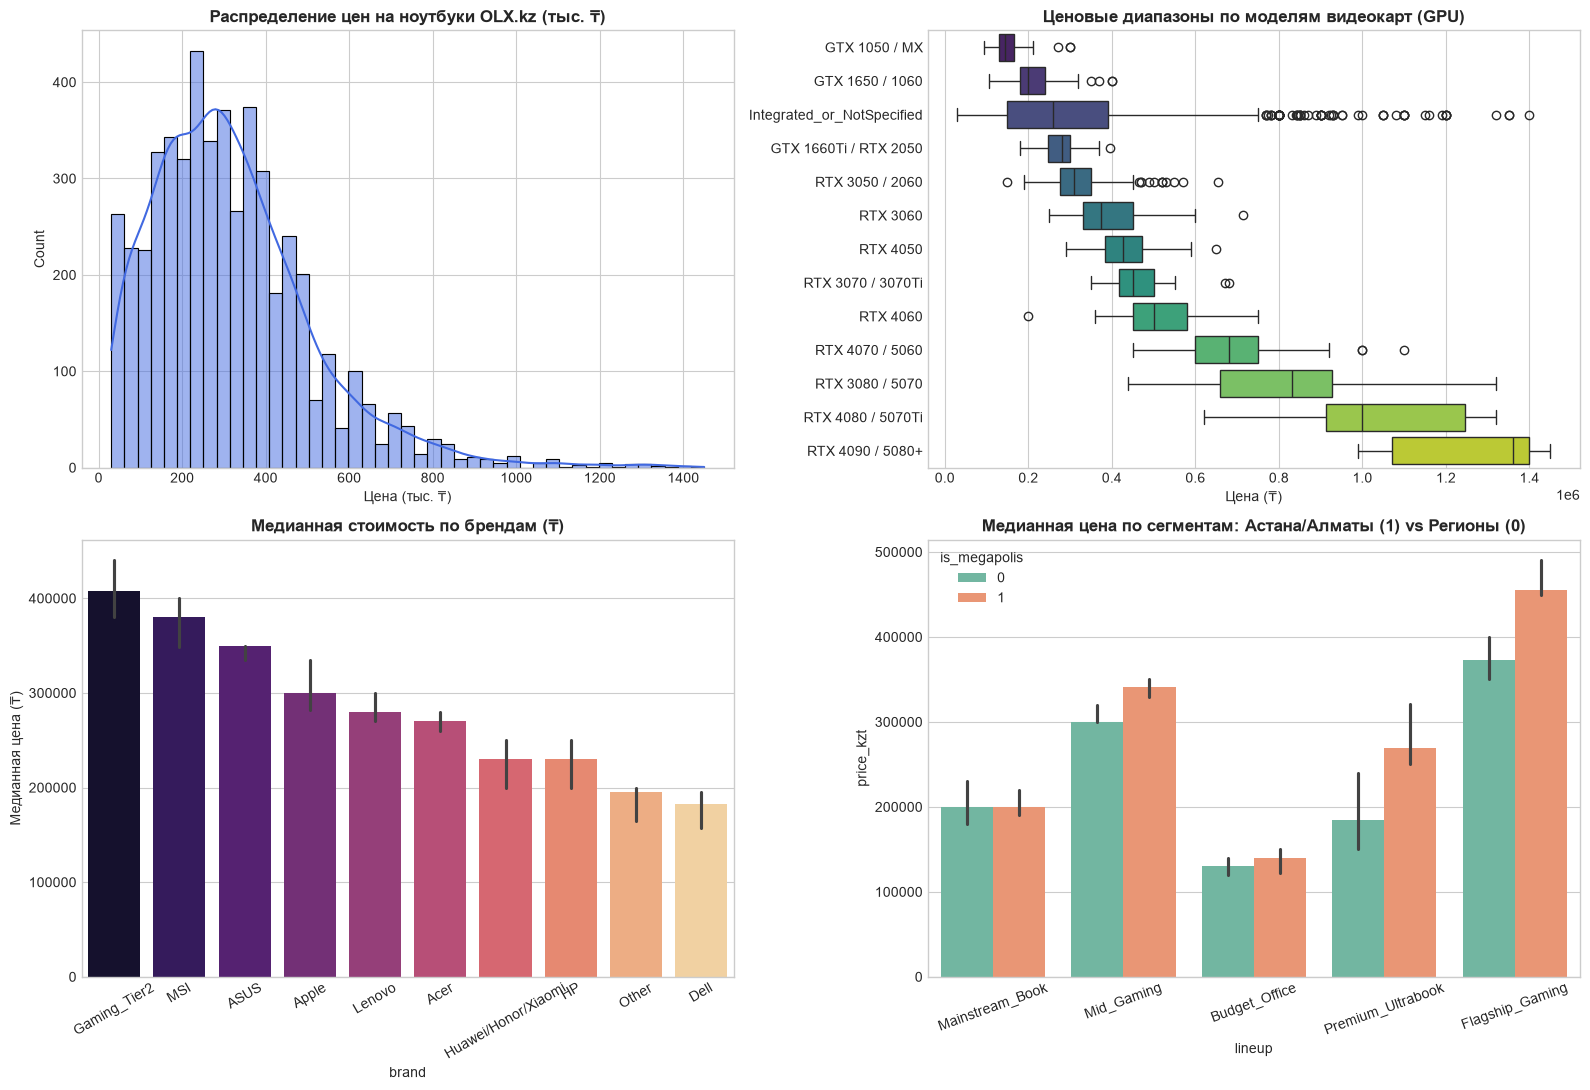

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Распределение цен (обычное vs логарифмическое)
sns.histplot(df_features['price_kzt'] / 1000, bins=45, kde=True, color='royalblue', ax=axes[0, 0])
axes[0, 0].set_title('Распределение цен на ноутбуки OLX.kz (тыс. ₸)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Цена (тыс. ₸)')

# 2. Медианная цена в зависимости от видеокарты
gpu_order = df_features.groupby('gpu_exact')['price_kzt'].median().sort_values().index
sns.boxplot(data=df_features, x='price_kzt', y='gpu_exact', order=gpu_order, palette='viridis', ax=axes[0, 1])
axes[0, 1].set_title('Ценовые диапазоны по моделям видеокарт (GPU)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Цена (₸)')
axes[0, 1].set_ylabel('')

# 3. Топ брендов по медианной цене
brand_order = df_features.groupby('brand')['price_kzt'].median().sort_values(ascending=False).index
sns.barplot(data=df_features, x='brand', y='price_kzt', order=brand_order, estimator=np.median, palette='magma', ax=axes[1, 0])
axes[1, 0].set_title('Медианная стоимость по брендам (₸)', fontsize=12, fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 0].set_ylabel('Медианная цена (₸)')

# 4. Сравнение цен по сегментам (Мегаполисы vs Регионы)
sns.barplot(data=df_features, x='lineup', y='price_kzt', hue='is_megapolis', estimator=np.median, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Медианная цена по сегментам: Астана/Алматы (1) vs Регионы (0)', fontsize=12, fontweight='bold')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('eda_summary_charts.png', dpi=150)
plt.show()

In [5]:
print("📊 ПРОВЕРКА СТАТИСТИЧЕСКИХ ГИПОТЕЗ (Уровень значимости alpha = 0.05)\n" + "="*75)

# Гипотеза 1: Различаются ли цены в Астане, Алматы и Шымкенте? (Тест Краскела-Уоллиса)
p_ast = df_features[df_features['city'] == 'Астана']['price_kzt']
p_alm = df_features[df_features['city'] == 'Алматы']['price_kzt']
p_shm = df_features[df_features['city'] == 'Шымкент']['price_kzt']
stat_kw, p_kw = stats.kruskal(p_ast, p_alm, p_shm)
print(f"Гипотеза 1 (Региональный фактор — Астана vs Алматы vs Шымкент):")
print(f"  • Медианы: Алматы = {p_alm.median():,.0f} ₸ | Астана = {p_ast.median():,.0f} ₸ | Шымкент = {p_shm.median():,.0f} ₸")
print(f"  • Критерий Краскела-Уоллиса: p-value = {p_kw:.4e} -> {'Подтверждена (разница значима)' if p_kw < 0.05 else 'Отклонена'}\n")

# Гипотеза 2: Снижают ли цену продавцы со словами «срочно / торг»? (Тест Манна-Уитни)
p_urg = df_features[df_features['is_urgent_or_bargain'] == 1]['price_kzt']
p_norm = df_features[df_features['is_urgent_or_bargain'] == 0]['price_kzt']
_, p_mw_urg = stats.mannwhitneyu(p_urg, p_norm, alternative='less')
disc = (1 - p_urg.median() / p_norm.median()) * 100
print(f"Гипотеза 2 (Фактор срочности и торга в заголовке):")
print(f"  • Медиана «Срочно/Торг»: {p_urg.median():,.0f} ₸ | Обычные: {p_norm.median():,.0f} ₸ (Скидка: -{disc:.1f}%)")
print(f"  • Односторонний U-тест Манна-Уитни: p-value = {p_mw_urg:.4f} -> {'Подтверждена (дают реальный дисконт)' if p_mw_urg < 0.05 else 'Отклонена'}\n")

# Гипотеза 3: Ломбарды и магазины продают более дешевый сегмент, чем частники
p_pawn = df_features[df_features['is_pawnshop_or_installment'] == 1]['price_kzt']
p_priv = df_features[df_features['is_pawnshop_or_installment'] == 0]['price_kzt']
_, p_mw_pawn = stats.mannwhitneyu(p_pawn, p_priv, alternative='two-sided')
print(f"Гипотеза 3 (Ломбарды/Рассрочка vs Частные продавцы):")
print(f"  • Медиана Ломбарды: {p_pawn.median():,.0f} ₸ | Частники: {p_priv.median():,.0f} ₸")
print(f"  • U-тест Манна-Уитни: p-value = {p_mw_pawn:.4e} -> {'Подтверждена' if p_mw_pawn < 0.05 else 'Отклонена'}")

📊 ПРОВЕРКА СТАТИСТИЧЕСКИХ ГИПОТЕЗ (Уровень значимости alpha = 0.05)
Гипотеза 1 (Региональный фактор — Астана vs Алматы vs Шымкент):
  • Медианы: Алматы = 300,000 ₸ | Астана = 300,000 ₸ | Шымкент = 200,000 ₸
  • Критерий Краскела-Уоллиса: p-value = 1.6868e-33 -> Подтверждена (разница значима)

Гипотеза 2 (Фактор срочности и торга в заголовке):
  • Медиана «Срочно/Торг»: 250,000 ₸ | Обычные: 290,000 ₸ (Скидка: -13.8%)
  • Односторонний U-тест Манна-Уитни: p-value = 0.0225 -> Подтверждена (дают реальный дисконт)

Гипотеза 3 (Ломбарды/Рассрочка vs Частные продавцы):
  • Медиана Ломбарды: 217,000 ₸ | Частники: 295,000 ₸
  • U-тест Манна-Уитни: p-value = 7.6613e-07 -> Подтверждена


In [6]:
# Для обучения ценового эталона берем объявления, где продавец указал характеристики железа (is_informative == 1)
df_model = df_features[df_features['is_informative'] == 1].copy()

cat_cols = ['brand', 'lineup', 'gpu_exact', 'cpu_family', 'city_clean']
num_cols = [
    'gpu_score', 'cpu_tier', 'est_year', 'ram_gb', 'ssd_gb',
    'screen_inch', 'is_high_hz_or_oled', 'is_new_sealed',
    'is_pawnshop_or_installment', 'is_urgent_or_bargain',
    'has_defect_or_old', 'is_megapolis', 'spec_detail_score'
]

# Разделяем на Train (80%) и Test (20%) со стратификацией по сегменту ноутбука
train_df, test_df = train_test_split(df_model, test_size=0.2, random_state=42, stratify=df_model['lineup'])

# 1. Справочный признак (Target Encoding без утечки данных): медианная цена аналогичной связки (Бренд + GPU + CPU) на Train
train_df['hw_group'] = train_df['brand'] + '_' + train_df['gpu_exact'] + '_' + train_df['cpu_family']
test_df['hw_group'] = test_df['brand'] + '_' + test_df['gpu_exact'] + '_' + test_df['cpu_family']

group_medians = train_df.groupby('hw_group')['price_kzt'].median()
gpu_medians = train_df.groupby('gpu_exact')['price_kzt'].median()
global_med = train_df['price_kzt'].median()

train_df['hw_market_anchor'] = train_df['hw_group'].map(group_medians).fillna(train_df['gpu_exact'].map(gpu_medians)).fillna(global_med)
test_df['hw_market_anchor'] = test_df['hw_group'].map(group_medians).fillna(test_df['gpu_exact'].map(gpu_medians)).fillna(global_med)

feature_cols = cat_cols + num_cols + ['hw_market_anchor']

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

# Целевая переменная в логарифмической шкале (чтобы модель одинаково точно предсказывала и за 100к, и за 1 млн тг)
y_train_log = np.log1p(train_df['price_kzt'].values)
y_test_actual = test_df['price_kzt'].values

# Кодировщики для линейной модели (OneHot + StandardScaler) и для деревянных моделей (OrdinalEncoder)
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler = StandardScaler()
X_train_lin = np.hstack([ohe.fit_transform(X_train[cat_cols]), scaler.fit_transform(X_train[num_cols + ['hw_market_anchor']])])
X_test_lin = np.hstack([ohe.transform(X_test[cat_cols]), scaler.transform(X_test[num_cols + ['hw_market_anchor']])])

ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_tree = X_train.copy()
X_test_tree = X_test.copy()
X_train_tree[cat_cols] = ord_enc.fit_transform(X_train[cat_cols])
X_test_tree[cat_cols] = ord_enc.transform(X_test[cat_cols])

# Тюнинг гиперпараметров Градиентного Бустинга через RandomizedSearchCV
param_dist = {
    'max_iter': [250, 350, 450],
    'learning_rate': [0.03, 0.05, 0.08],
    'max_leaf_nodes': [25, 31, 45],
    'min_samples_leaf': [5, 10, 15],
    'l2_regularization': [1.0, 2.5, 5.0]
}
search_gbm = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_distributions=param_dist, n_iter=12, scoring='neg_mean_absolute_error', cv=4, random_state=42, n_jobs=-1
)
search_gbm.fit(X_train_tree, y_train_log)
best_gbm_params = search_gbm.best_params_
print(f"🔧 Лучшие гиперпараметры бустинга после тюнинга: {best_gbm_params}\n")

# Сравниваем 3 модели
candidates = {
    "1. Baseline: Ridge Regression": (Ridge(alpha=15.0), X_train_lin, X_test_lin),
    "2. Random Forest Regressor": (RandomForestRegressor(n_estimators=300, max_depth=16, min_samples_leaf=2, random_state=42, n_jobs=-1), X_train_tree, X_test_tree),
    "3. Tuned Gradient Boosting (HistGBM)": (search_gbm.best_estimator_, X_train_tree, X_test_tree)
}

metrics_table = []
for name, (model, x_tr, x_te) in candidates.items():
    model.fit(x_tr, y_train_log)
    preds_kzt = np.expm1(model.predict(x_te))
    metrics_table.append({
        'Модель': name,
        'MAE (₸)': round(mean_absolute_error(y_test_actual, preds_kzt)),
        'MAPE (%)': round(mean_absolute_percentage_error(y_test_actual, preds_kzt) * 100, 2),
        'R2 Score': round(r2_score(y_test_actual, preds_kzt), 4)
    })

df_metrics = pd.DataFrame(metrics_table)
display(df_metrics)

🔧 Лучшие гиперпараметры бустинга после тюнинга: {'min_samples_leaf': 5, 'max_leaf_nodes': 25, 'max_iter': 350, 'learning_rate': 0.03, 'l2_regularization': 1.0}



,Модель,MAE (₸),MAPE (%),R2 Score
0,1. Baseline: Ridge Regression,64787,19.30,0.7472
1,2. Random Forest Regressor,51406,16.53,0.8449
2,3. Tuned Gradient Boosting (HistGBM),49712,15.68,0.8597


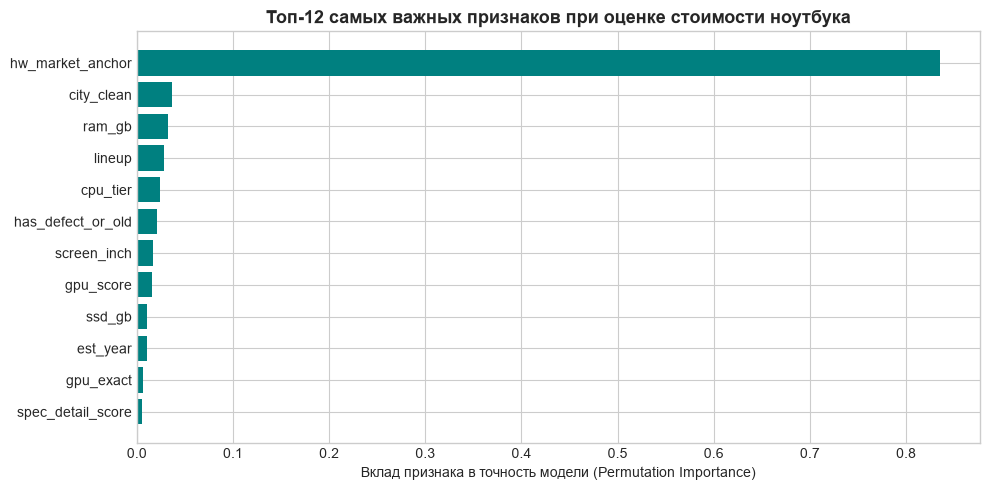

In [7]:
best_model = candidates["3. Tuned Gradient Boosting (HistGBM)"][0]
perm_imp = permutation_importance(best_model, X_test_tree, np.log1p(y_test_actual), n_repeats=10, random_state=42, n_jobs=-1)

imp_df = pd.DataFrame({
    'Признак': feature_cols,
    'Важность': perm_imp.importances_mean
}).sort_values(by='Важность', ascending=True).tail(12)

plt.figure(figsize=(10, 5))
plt.barh(imp_df['Признак'], imp_df['Важность'], color='teal')
plt.title('Топ-12 самых важных признаков при оценке стоимости ноутбука', fontsize=13, fontweight='bold')
plt.xlabel('Вклад признака в точность модели (Permutation Importance)')
plt.tight_layout()
plt.show()

In [ ]:
# Обучаем 3 квантильные модели для построения ценового коридора:
# Q15 (15-й перцентиль) — цена быстрого выкупа для перепродажи
# Q50 (медиана) — справедливая рыночная стоимость
# Q85 (85-й перцентиль) — потолок рынка (выше него — Оверпрайс)
quantile_models = {}
for q, label in [(0.15, 'q15'), (0.50, 'q50'), (0.85, 'q85')]:
    qm = HistGradientBoostingRegressor(loss='quantile', quantile=q, **best_gbm_params, random_state=42)
    qm.fit(X_train_tree, y_train_log)
    quantile_models[label] = qm

# Предсказываем коридор цен на тестовой выборке
scored_deals = test_df.copy()
scored_deals['fast_buyout_q15'] = np.round(np.expm1(quantile_models['q15'].predict(X_test_tree)), -3)
scored_deals['fair_price_q50'] = np.round(np.expm1(quantile_models['q50'].predict(X_test_tree)), -3)
scored_deals['market_ceiling_q85'] = np.round(np.expm1(quantile_models['q85'].predict(X_test_tree)), -3)

# Гарантируем логический порядок границ коридора
scored_deals['fast_buyout_q15'] = np.minimum(scored_deals['fast_buyout_q15'], np.round(scored_deals['fair_price_q50'] * 0.90, -3))
scored_deals['market_ceiling_q85'] = np.maximum(scored_deals['market_ceiling_q85'], np.round(scored_deals['fair_price_q50'] * 1.10, -3))

# Считаем потенциальную маржу реселлера в тенге и процентах
scored_deals['potential_profit_kzt'] = scored_deals['fair_price_q50'] - scored_deals['price_kzt']
scored_deals['discount_pct'] = np.round((scored_deals['potential_profit_kzt'] / scored_deals['fair_price_q50']) * 100, 1)

def get_deal_verdict(row):
    if row['price_kzt'] <= row['fast_buyout_q15'] and row['has_defect_or_old'] == 0 and row['discount_pct'] <= 45:
        return 'ГОРЯЧИЙ ЛОТ (Выкуп)'
    elif row['discount_pct'] >= 10.0 and row['has_defect_or_old'] == 0:
        return 'Выгодная сделка'
    elif row['price_kzt'] <= row['market_ceiling_q85']:
        return 'В рынке'
    else:
        return 'Оверпрайс'

scored_deals['deal_verdict'] = scored_deals.apply(get_deal_verdict, axis=1)

# Сохраняем витрину оцененных сделок и обученные модели для Streamlit (app.py)
scored_deals.to_csv('../data/olx_test_scored_deals.csv', index=False)

artifacts = {
    'quantile_models': quantile_models,
    'ordinal_encoder': ord_enc,
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'feature_cols': feature_cols,
    'group_medians': group_medians.to_dict(),
    'gpu_medians': gpu_medians.to_dict(),
    'global_med': global_med
}
joblib.dump(artifacts, '../models/laptop_scorer_artifacts.pkl')

print("✅ Модели сохранены в 'laptop_scorer_artifacts.pkl', витрина сделок — в 'olx_test_scored_deals.csv'!")
print("\n🔥 ТОП-5 НАЙДЕННЫХ ГОРЯЧИХ СДЕЛОК ДЛЯ РЕСЕЛЛЕРА:")
cols_view = ['title', 'city', 'price_kzt', 'fast_buyout_q15', 'fair_price_q50', 'potential_profit_kzt', 'discount_pct', 'deal_verdict']
display(scored_deals[scored_deals['deal_verdict'] == 'ГОРЯЧИЙ ЛОТ (Выкуп)'].sort_values(by='potential_profit_kzt', ascending=False)[cols_view].head(5))

✅ Модели сохранены в 'laptop_scorer_artifacts.pkl', витрина сделок — в 'olx_test_scored_deals.csv'!

🔥 ТОП-5 НАЙДЕННЫХ ГОРЯЧИХ СДЕЛОК ДЛЯ РЕСЕЛЛЕРА:


,title,city,price_kzt,fast_buyout_q15,fair_price_q50,potential_profit_kzt,discount_pct,deal_verdict
2531,Игровой ноутбук ASUS ROG STRIX RTX4080,Алматы,620000,810000.0,900000.0,280000.0,31.1,ГОРЯЧИЙ ЛОТ (Выкуп)
1163,Забудьте про лаги: ASUS V16 на RTX 5070 | Inte...,Астана,599500,741000.0,823000.0,223500.0,27.2,ГОРЯЧИЙ ЛОТ (Выкуп)
1052,Ноутбук Gigabyte Aorus 15 BSF (БУ) - Core i7-1...,Астана,450000,581000.0,646000.0,196000.0,30.3,ГОРЯЧИЙ ЛОТ (Выкуп)
2839,Игровой ноутбук ASUS V16 на RTX 5070 | Core 5 ...,Астана,629500,708000.0,787000.0,157500.0,20.0,ГОРЯЧИЙ ЛОТ (Выкуп)
619,"Новые Lenovo V15 (Ryzen 7 7730u, 16 Gb DDR5, 5...",Шымкент,339990,389000.0,486000.0,146010.0,30.0,ГОРЯЧИЙ ЛОТ (Выкуп)
